
=== Downloading genomes from NCBI ===
[1/46] Paenibacillus litoralis: 1 sequence(s), 8,741,851 bp
[2/46] Paenibacillus bovis: 1 sequence(s), 5,354,277 bp
[3/46] Paenibacillus chitinolyticus: 1 sequence(s), 6,509,090 bp
[4/46] Paenibacillus graminis: 1 sequence(s), 7,166,464 bp
[5/46] Paenibacillus durus: 1 sequence(s), 6,038,347 bp
[6/46] Paenibacillus sophorae: 1 sequence(s), 5,867,720 bp
[7/46] Paenibacillus kribbensis: 1 sequence(s), 5,778,702 bp
[8/46] Paenibacillus odorifer: 1 sequence(s), 6,812,473 bp
[9/46] Paenibacillus chondroitinus: 1 sequence(s), 8,010,791 bp
[10/46] Paenibacillus riograndensis: 1 sequence(s), 7,919,576 bp
[11/46] Paenibacillus polymyxa: 1 sequence(s), 5,921,998 bp
[12/46] Paenibacillus kyungheensis: 1 sequence(s), 5,260,882 bp
[13/46] Paenibacillus donghaensis: 1 sequence(s), 8,542,333 bp
[14/46] Paenibacillus borealis: 1 sequence(s), 8,156,808 bp
[15/46] Paenibacillus psychroresistens: 1 sequence(s), 8,101,785 bp
[16/46] Paenibacillus andongensis: 1 seque

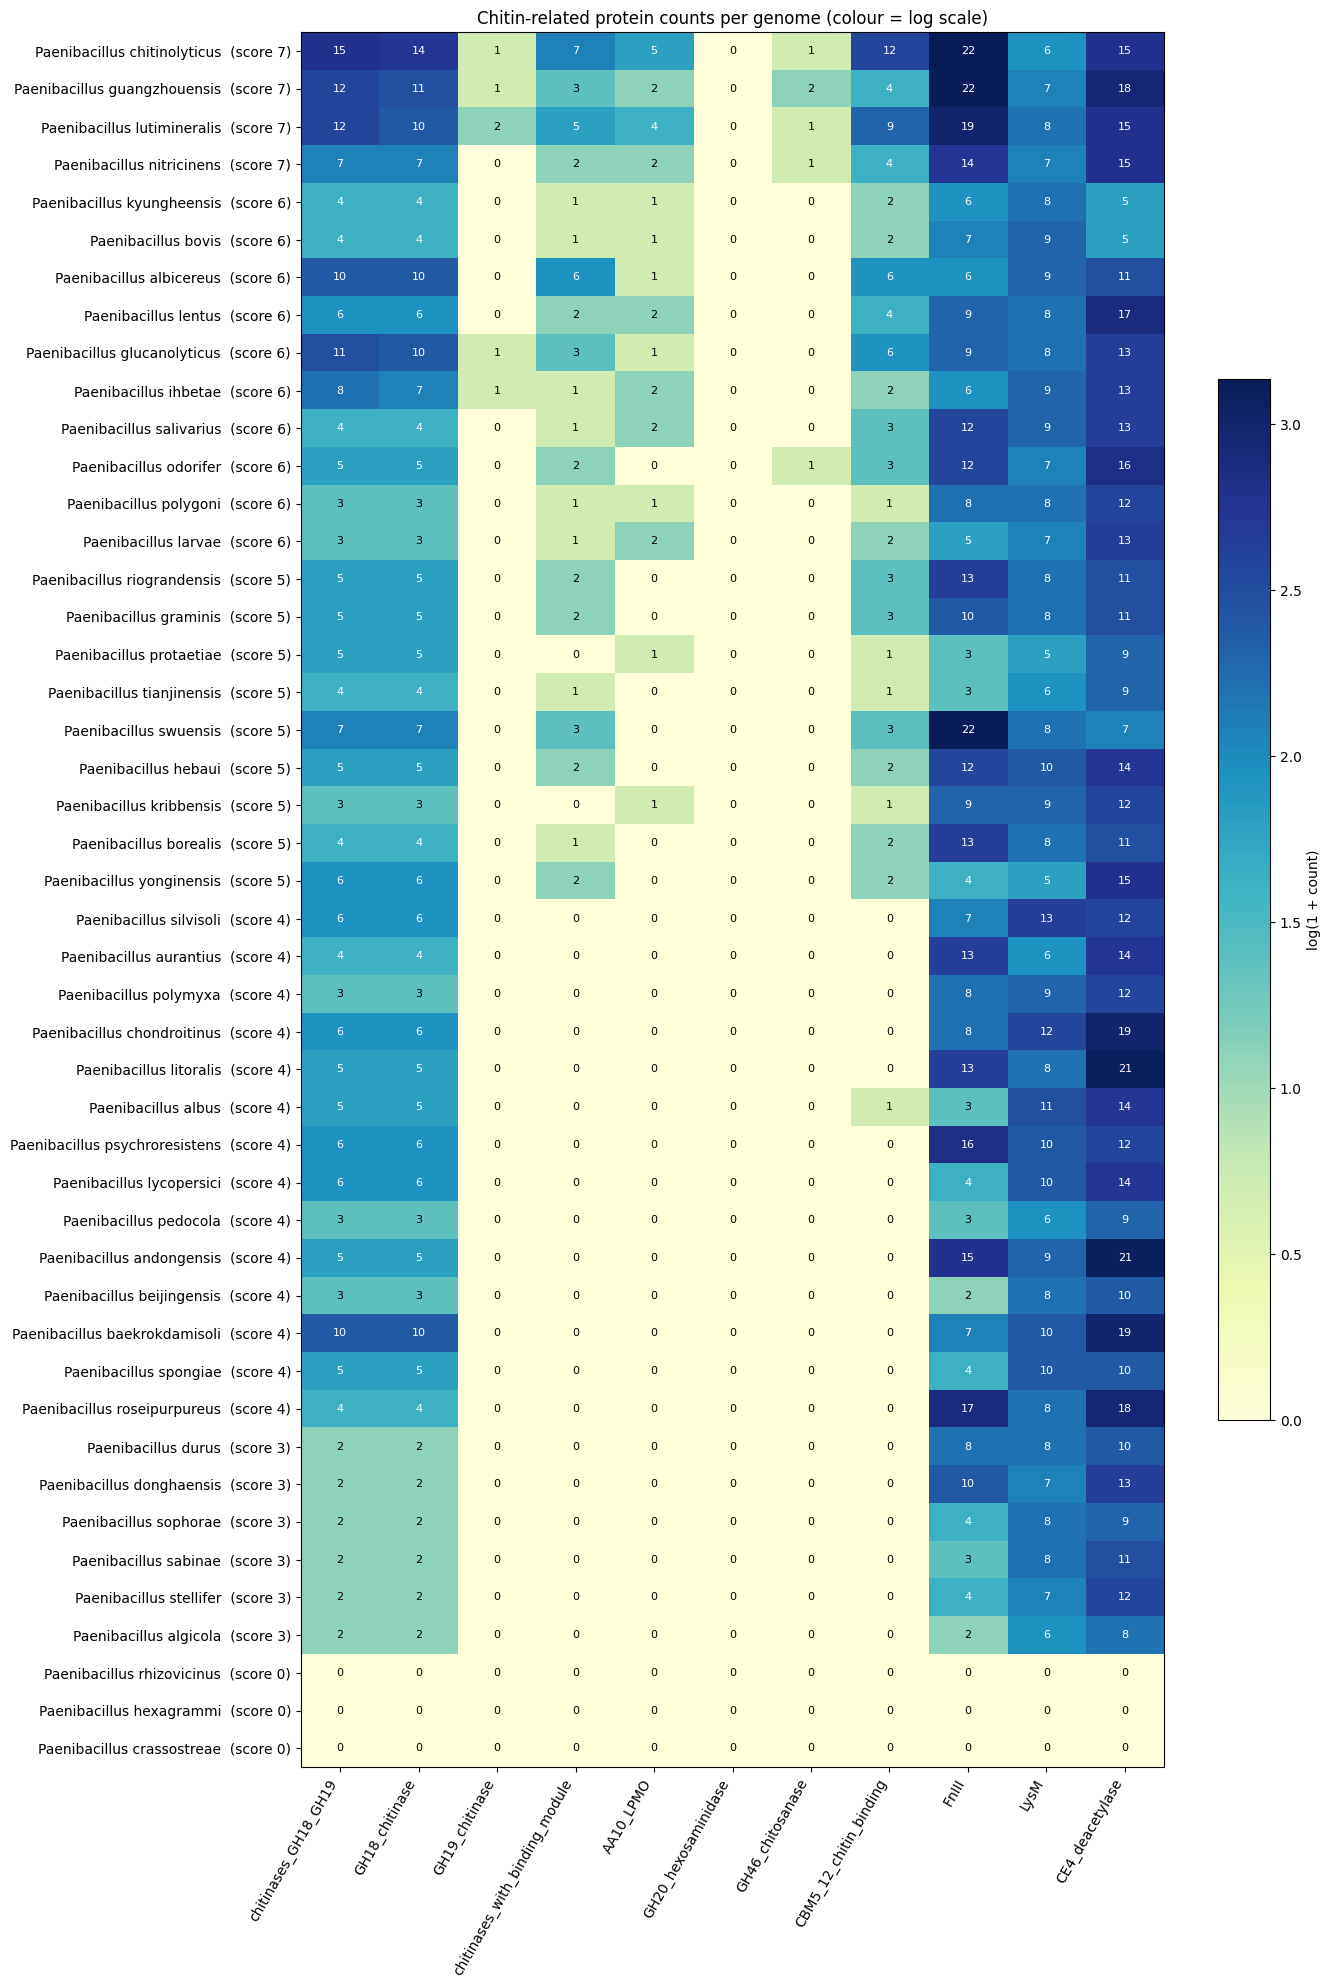

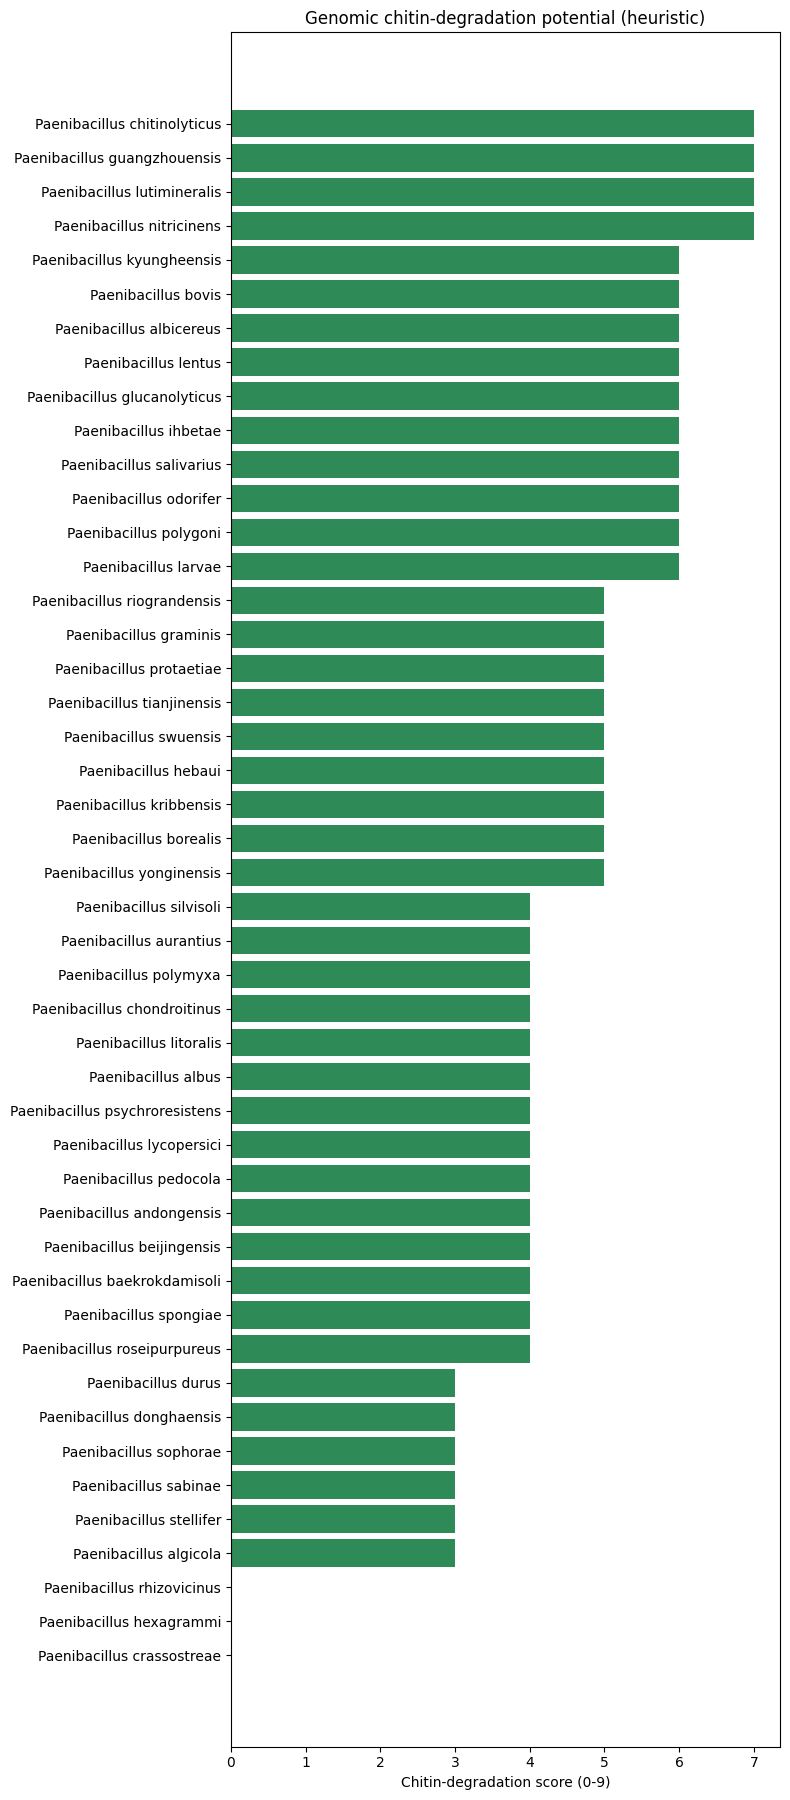


Done. Tables and figures are in 'results'.
Reminder: gene presence indicates potential, not proof, of chitin degradation; confirm key strains with a chitin plate or enzyme assay.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
"""
Chitin-degradation screen for Paenibacillus genomes (Google Colab, pure Python)
==============================================================================
What it does
    1. Downloads each genome from NCBI by accession (no manual download needed)
    2. Predicts genes with pyrodigal and translates them to proteins
    3. Searches the proteins with pyhmmer against Pfam profiles for chitin-related
       enzymes and binding modules (GH18, GH19, GH20, AA10/LPMO, CBM5/12, FnIII,
       LysM, CE4, GH46)
    4. Builds a genome x feature table, a transparent chitin-degradation score,
       a heatmap and a ranking
    5. OPTIONAL: if you provide phenotype labels, trains and cross-validates a
       logistic-regression model

How to use in Colab
    1. New notebook -> paste this whole script into ONE cell
    2. Add the rest of your accessions to GENOMES below (31 more, from your list of 46)
    3. (Optional) set EMAIL, and LABELS_CSV (upload the file in the Colab file panel first)
    4. Run. results.zip downloads at the end.

Everything needs internet access (Colab has it). Packages installed automatically:
pyrodigal, pyhmmer.
"""
import gzip
import io
import re
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------
# SETTINGS
# ----------------------------------------------------------------------
# A value can be one accession (string) or a list of accessions (chromosome + plasmids).
GENOMES = {
     "Paenibacillus litoralis": "NZ_CP176395.1",
    "Paenibacillus bovis": "NZ_CP013023.1",
    "Paenibacillus chitinolyticus": "NZ_CP026520.1",
    "Paenibacillus graminis": "NZ_CP009287.1",
    "Paenibacillus durus": "NZ_CP009288.1",
    "Paenibacillus sophorae": "NZ_CP076607.1",
    "Paenibacillus kribbensis": "NZ_CP020028.1",
    "Paenibacillus odorifer": "NZ_CP009428.1",
    "Paenibacillus chondroitinus": "NZ_CM137256.1",
    "Paenibacillus riograndensis": "NZ_LN831776.1",
    "Paenibacillus polymyxa": "NZ_CP024795.1",
    "Paenibacillus kyungheensis": "NZ_CP117416.1",
    "Paenibacillus donghaensis": "NZ_CP021780.1",
    "Paenibacillus borealis": "NZ_CP009285.1",
    "Paenibacillus psychroresistens": "NZ_CP034235.1",
    "Paenibacillus andongensis": "NZ_CP104467.1",
    "Paenibacillus spongiae": "NZ_CP091430.1",
    "Paenibacillus baekrokdamisoli": "NZ_AP019308.1",
    "Paenibacillus hebaui": "NZ_CP196836.1",
    "Paenibacillus rhizovicinus": "NZ_CP048288.1",
    "Paenibacillus guangzhouensis": "NZ_CP045293.1",
    "Paenibacillus yonginensis": "NZ_CP014167.1",
    "Paenibacillus swuensis": "NZ_CP011388.1",
    "Paenibacillus albicereus": "NZ_CP051428.1",
    "Paenibacillus sabinae": "NZ_CP004078.1	",
    "Paenibacillus lentus": "NZ_CP034248.1",
    "Paenibacillus salivarius": "NZ_CP195592.1",
    "Paenibacillus stellifer": "NZ_CP009286.1",
    "Paenibacillus beijingensis": "NZ_CP011058.1",
    "Paenibacillus roseipurpureus": "NZ_CP130319.1",
    "Paenibacillus tianjinensis": "NZ_CP070969.1",
    "Paenibacillus aurantius": "NZ_CP130318.1",
    "Paenibacillus pedocola": "	NZ_CP134223.1",
    "Paenibacillus lutimineralis": "NZ_CP034346.1",
    "Paenibacillus hexagrammi": "NZ_CP090979.1",
    "Paenibacillus ihbetae": "NZ_CP016809.1",
    "Paenibacillus albus": "NZ_CP034437.1",
    "Paenibacillus silvisoli": "NZ_CP133017.1",
    "Paenibacillus lycopersici": "NZ_CP048209.1	",
    "Paenibacillus stellifer": "NZ_CP009286.1",
    "Paenibacillus nitricinens": "NZ_CP183948.1",
    "Paenibacillus glucanolyticus": "NZ_CP015286.1",
    "Paenibacillus rhizovicinus": "NZ_CP048288.1",
    "Paenibacillus larvae": "NZ_CP019687.1",
    "Paenibacillus protaetiae": "NZ_CP035492.1",
    "Paenibacillus algicola": "NZ_CP040396.1	",
    "Paenibacillus crassostreae": "NZ_CP017773.1	",
    "Paenibacillus polygoni": "NZ_CP127162.1",
}

EMAIL = ""            # optional but polite: NCBI asks for a contact e-mail
LABELS_CSV = None     # optional, e.g. "labels.csv" with columns: genome,chitin_degrader (1/0 or yes/no)
OUT = Path("results")
GENOME_DIR = Path("genomes")
HMM_DIR = Path("hmm_db")

# Pfam profiles used (accession -> short feature name)
PROFILES = {
    "PF00704": "GH18_chitinase",
    "PF00182": "GH19_chitinase",
    "PF00728": "GH20_hexosaminidase",
    "PF03067": "AA10_LPMO",
    "PF02839": "CBM5_12_chitin_binding",
    "PF00041": "FnIII",
    "PF01476": "LysM",
    "PF01522": "CE4_deacetylase",
    "PF01374": "GH46_chitosanase",
}

# Transparent scoring (edit freely). Max = 9.
#   chitinase (GH18/GH19)      : +3 if >=1 copy, +1 more if >=3 copies
#   chitinase + binding module : +1 (same protein also carries CBM5/12 or FnIII)
#   AA10 LPMO                  : +1
#   GH20 hexosaminidase        : +2 (chitobiose -> GlcNAc)
#   GH46 chitosanase           : +1
SCORE_WEIGHTS = {"chitinase_present": 3, "chitinase_multi": 1, "chitinase_binding": 1,
                 "AA10_LPMO": 1, "GH20_hexosaminidase": 2, "GH46_chitosanase": 1}


# ----------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------
def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])


def ensure_packages():
    for mod, pkg in (("pyrodigal", "pyrodigal"), ("pyhmmer", "pyhmmer"), ("requests", "requests")):
        try:
            __import__(mod)
        except ImportError:
            print(f"Installing {pkg} ...")
            pip_install(pkg)


def as_list(x):
    return [x] if isinstance(x, str) else list(x)


# ----------------------------------------------------------------------
# 1. Download genomes
# ----------------------------------------------------------------------
def fetch_fasta(acc, tries=3):
    import requests
    url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
    params = {"db": "nuccore", "id": acc, "rettype": "fasta", "retmode": "text", "tool": "chitin_screen"}
    if EMAIL:
        params["email"] = EMAIL
    last = None
    for k in range(tries):
        try:
            r = requests.get(url, params=params, timeout=180)
            if r.status_code == 200 and r.text.startswith(">"):
                return r.text
            last = f"HTTP {r.status_code}: {r.text[:100]!r}"
        except Exception as e:  # network problems
            last = repr(e)
        time.sleep(2 * (k + 1))
    raise RuntimeError(f"could not download {acc}: {last}")


def parse_fasta_text(text):
    seqs, name, buf = {}, None, []
    for line in text.splitlines():
        if line.startswith(">"):
            if name:
                seqs[name] = "".join(buf).upper()
            name, buf = line[1:].split()[0], []
        elif name:
            buf.append(line.strip())
    if name:
        seqs[name] = "".join(buf).upper()
    return seqs


def load_genomes():
    GENOME_DIR.mkdir(exist_ok=True)
    genomes, failed = {}, {}
    for i, (name, accs) in enumerate(GENOMES.items(), 1):
        contigs = {}
        try:
            for acc in as_list(accs):
                path = GENOME_DIR / f"{acc}.fasta"
                if not path.exists():
                    path.write_text(fetch_fasta(acc))
                    time.sleep(0.4)     # stay under NCBI's 3 requests/second limit
                contigs.update(parse_fasta_text(path.read_text()))
            genomes[name] = contigs
            print(f"[{i}/{len(GENOMES)}] {name}: {len(contigs)} sequence(s), "
                  f"{sum(len(s) for s in contigs.values()):,} bp")
        except Exception as e:
            failed[name] = str(e)
            print(f"[{i}/{len(GENOMES)}] {name}: FAILED - {e}")
    return genomes, failed


# ----------------------------------------------------------------------
# 2. Gene prediction (pyrodigal)
# ----------------------------------------------------------------------
def predict_proteins(contigs):
    """Return list of dicts: contig, start, end, strand, protein."""
    import pyrodigal
    seqs = list(contigs.items())
    total = sum(len(s) for _, s in seqs)
    finder = None
    if total >= 100_000:
        try:
            finder = pyrodigal.GeneFinder(meta=False)
            finder.train(*[s for _, s in seqs])
        except Exception:
            finder = None
    if finder is None:                       # tiny / odd sequences: metagenomic models
        finder = pyrodigal.GeneFinder(meta=True)
    prots = []
    for cname, s in seqs:
        for g in finder.find_genes(s):
            aa = g.translate().rstrip("*")
            if len(aa) >= 30:
                prots.append({"contig": cname, "start": g.begin, "end": g.end,
                              "strand": "+" if g.strand == 1 else "-", "protein": aa})
    return prots


# ----------------------------------------------------------------------
# 3. HMM profiles and search (pyhmmer)
# ----------------------------------------------------------------------
def fetch_hmm(acc):
    import requests
    urls = [f"https://www.ebi.ac.uk/interpro/api/entry/pfam/{acc}?annotation=hmm",
            f"https://www.ebi.ac.uk/interpro/wwwapi/entry/pfam/{acc}?annotation=hmm"]
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120)
            if r.status_code == 200 and r.content:
                data = r.content
                if data[:2] == b"\x1f\x8b":
                    data = gzip.decompress(data)
                if data.startswith(b"HMMER"):
                    return data
                last = f"unexpected content from {u}"
            else:
                last = f"HTTP {r.status_code} from {u}"
        except Exception as e:
            last = repr(e)
    raise RuntimeError(f"could not download {acc}: {last}")


def load_hmms():
    import pyhmmer
    HMM_DIR.mkdir(exist_ok=True)
    hmms, missing = [], []
    for acc, feat in PROFILES.items():
        path = HMM_DIR / f"{acc}.hmm"
        try:
            if not path.exists():
                path.write_bytes(fetch_hmm(acc))
            with pyhmmer.plan7.HMMFile(str(path)) as hf:
                h = next(iter(hf))
            hmms.append((feat, h))
            print(f"  profile {acc} -> {feat} (model name: {h.name.decode() if isinstance(h.name, bytes) else h.name})")
        except Exception as e:
            missing.append(acc)
            print(f"  WARNING profile {acc} ({feat}) unavailable: {e}")
    if missing:
        print("\nTip: you can place your own HMM files named PFxxxxx.hmm in the 'hmm_db' folder "
              "(Pfam download page) and re-run.")
    return hmms


def search_proteins(genome_name, prots, hmms):
    """Return rows (genome, prot_idx, feature, score, evalue) for hits passing the cut-offs."""
    import pyhmmer
    if not prots:
        return []
    amino = pyhmmer.easel.Alphabet.amino()
    block = pyhmmer.easel.DigitalSequenceBlock(
        amino, [pyhmmer.easel.TextSequence(name=str(i).encode(), sequence=p["protein"]).digitize(amino)
                for i, p in enumerate(prots)])
    models = [h for _, h in hmms]
    use_ga = all(getattr(h.cutoffs, "gathering", None) is not None for h in models)
    kw = {"bit_cutoffs": "gathering"} if use_ga else {"E": 1e-5}
    rows = []
    for (feat, _), tophits in zip(hmms, pyhmmer.hmmsearch(models, block, cpus=0, **kw)):
        for hit in tophits:
            if use_ga and not hit.included:
                continue
            if not use_ga and hit.evalue > 1e-5:
                continue
            name = hit.name.decode() if isinstance(hit.name, bytes) else hit.name
            rows.append({"genome": genome_name, "prot_idx": int(name), "feature": feat,
                         "bitscore": round(hit.score, 1), "evalue": hit.evalue})
    return rows


# ----------------------------------------------------------------------
# 4. Feature table and score
# ----------------------------------------------------------------------
def build_feature_table(hits, genome_names, proteins_per_genome):
    feats = list(PROFILES.values())
    table = pd.DataFrame(0, index=genome_names, columns=feats, dtype=int)
    chit, chit_bind = {g: 0 for g in genome_names}, {g: 0 for g in genome_names}
    if len(hits):
        d = hits.drop_duplicates(["genome", "prot_idx", "feature"])
        for (g, f), n in d.groupby(["genome", "feature"]).size().items():
            table.loc[g, f] = n
        for (g, p), sub in d.groupby(["genome", "prot_idx"]):
            fs = set(sub["feature"])
            if fs & {"GH18_chitinase", "GH19_chitinase"}:
                chit[g] += 1
                if fs & {"CBM5_12_chitin_binding", "FnIII"}:
                    chit_bind[g] += 1
    table["chitinases_GH18_GH19"] = pd.Series(chit)
    table["chitinases_with_binding_module"] = pd.Series(chit_bind)
    table["total_proteins_predicted"] = pd.Series(proteins_per_genome)
    return table


def chitin_score(table):
    w = SCORE_WEIGHTS
    s = pd.Series(0.0, index=table.index)
    s += w["chitinase_present"] * (table["chitinases_GH18_GH19"] >= 1)
    s += w["chitinase_multi"] * (table["chitinases_GH18_GH19"] >= 3)
    s += w["chitinase_binding"] * (table["chitinases_with_binding_module"] >= 1)
    s += w["AA10_LPMO"] * (table["AA10_LPMO"] >= 1)
    s += w["GH20_hexosaminidase"] * (table["GH20_hexosaminidase"] >= 1)
    s += w["GH46_chitosanase"] * (table["GH46_chitosanase"] >= 1)
    return s.astype(int)


def plot_heatmap(table, score):
    cols = ["chitinases_GH18_GH19", "GH18_chitinase", "GH19_chitinase", "chitinases_with_binding_module",
            "AA10_LPMO", "GH20_hexosaminidase", "GH46_chitosanase", "CBM5_12_chitin_binding",
            "FnIII", "LysM", "CE4_deacetylase"]
    order = score.sort_values(ascending=False).index
    data = table.loc[order, cols]
    fig, ax = plt.subplots(figsize=(1.0 * len(cols) + 3, 0.38 * len(order) + 2.5))
    im = ax.imshow(np.log1p(data.values), cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right")
    ax.set_yticks(range(len(order)), [f"{g}  (score {score[g]})" for g in order])
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, int(data.values[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if np.log1p(data.values[i, j]) > 1.6 else "black")
    ax.set_title("Chitin-related protein counts per genome (colour = log scale)")
    fig.colorbar(im, ax=ax, shrink=0.6, label="log(1 + count)")
    fig.tight_layout()
    fig.savefig(OUT / "chitin_heatmap.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 0.35 * len(order) + 2))
    ax.barh(list(order)[::-1], score[order].values[::-1], color="seagreen")
    ax.set_xlabel(f"Chitin-degradation score (0-{sum(SCORE_WEIGHTS.values())})")
    ax.set_title("Genomic chitin-degradation potential (heuristic)")
    fig.tight_layout()
    fig.savefig(OUT / "chitin_score_ranking.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ----------------------------------------------------------------------
# 5. Optional model
# ----------------------------------------------------------------------
def train_model(table, score):
    if not LABELS_CSV:
        return
    try:
        from sklearn.linear_model import LogisticRegression
        from sklearn.model_selection import LeaveOneOut, cross_val_predict
        from sklearn.preprocessing import StandardScaler
        from sklearn.pipeline import make_pipeline
    except ImportError:
        print("scikit-learn not available; skipping the model.")
        return
    lab = pd.read_csv(LABELS_CSV)
    lab.columns = [c.strip().lower() for c in lab.columns]
    y = lab.set_index("genome")["chitin_degrader"].astype(str).str.lower().map(
        {"1": 1, "yes": 1, "y": 1, "true": 1, "0": 0, "no": 0, "n": 0, "false": 0}).dropna().astype(int)
    common = [g for g in table.index if g in y.index]
    print(f"\nLabelled genomes found in the table: {len(common)} of {len(table)}")
    if len(common) < 8 or y[common].nunique() < 2 or y[common].value_counts().min() < 2:
        print("Not enough labelled genomes of both classes for a meaningful model (need >=2 of each, ideally >=10).")
        return
    X = table.loc[common].drop(columns=["total_proteins_predicted"])
    X = np.log1p(X)
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000, C=0.5))
    pred = cross_val_predict(model, X, y[common], cv=LeaveOneOut())
    acc = (pred == y[common].values).mean()
    print(f"Leave-one-genome-out accuracy: {acc:.2f} ({int((pred == y[common].values).sum())}/{len(common)})")
    print(pd.crosstab(pd.Series(y[common].values, name="true"), pd.Series(pred, name="predicted")))
    base = ((score[common] >= 3).astype(int).values == y[common].values).mean()
    print(f"For comparison, the simple rule 'score >= 3' scores {base:.2f}")
    model.fit(X, y[common])
    coefs = pd.Series(model[-1].coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
    coefs.to_csv(OUT / "model_coefficients.csv", header=["coefficient"])
    print("\nStrongest features:\n", coefs.head(8).round(2).to_string())
    pd.DataFrame({"genome": common, "true": y[common].values, "predicted_loo": pred}).to_csv(
        OUT / "model_predictions.csv", index=False)


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    OUT.mkdir(exist_ok=True)
    ensure_packages()

    print("\n=== Downloading genomes from NCBI ===")
    genomes, failed = load_genomes()
    if not genomes:
        raise SystemExit("No genome could be downloaded. Check the internet connection and the accessions.")

    print("\n=== Loading HMM profiles ===")
    hmms = load_hmms()
    if not hmms:
        raise SystemExit("No HMM profiles available; cannot continue (see tip above).")

    print("\n=== Predicting genes and searching proteins ===")
    all_rows, proteins_per_genome, protein_info = [], {}, []
    for i, (name, contigs) in enumerate(genomes.items(), 1):
        prots = predict_proteins(contigs)
        proteins_per_genome[name] = len(prots)
        rows = search_proteins(name, prots, hmms)
        for r in rows:
            p = prots[r["prot_idx"]]
            r.update({"contig": p["contig"], "start": p["start"], "end": p["end"], "strand": p["strand"],
                      "length_aa": len(p["protein"])})
        all_rows += rows
        print(f"[{i}/{len(genomes)}] {name}: {len(prots):,} proteins, {len(rows)} domain hits")

    hits = pd.DataFrame(all_rows)
    hits.to_csv(OUT / "domain_hits.csv", index=False)

    table = build_feature_table(hits, list(genomes), proteins_per_genome)
    score = chitin_score(table)
    table["chitin_score"] = score
    table.sort_values("chitin_score", ascending=False).to_csv(OUT / "chitin_feature_table.csv")

    print("\n=== Ranking ===")
    show_cols = ["chitin_score", "chitinases_GH18_GH19", "chitinases_with_binding_module",
                 "AA10_LPMO", "GH20_hexosaminidase", "GH46_chitosanase"]
    print(table.sort_values("chitin_score", ascending=False)[show_cols].to_string())
    if failed:
        print("\nGenomes that could not be downloaded:", failed)
        pd.Series(failed, name="error").to_csv(OUT / "failed_downloads.csv")

    plot_heatmap(table.drop(columns=["chitin_score"]), score)
    train_model(table.drop(columns=["chitin_score"]), score)

    print(f"\nDone. Tables and figures are in '{OUT}'.")
    print("Reminder: gene presence indicates potential, not proof, of chitin degradation; "
          "confirm key strains with a chitin plate or enzyme assay.")
    try:
        from google.colab import files
        shutil.make_archive("results", "zip", OUT)
        files.download("results.zip")
    except ImportError:
        pass


if __name__ == "__main__":
    main()